# Exact and Monte Carlo overlap: eight-disorder benchmark

**2 × 2 periodic Kagome · 12 spins · Gamma = 0.5 · h = 0.15**

This is the first executed step of the [research plan](spin_glass_phase_research_plan.ipynb).
Both methods use the same eight random antiferromagnetic bond samples, IDs 50000–50007,
with bond strengths uniformly distributed between 0.5 and 1.5.

Exact values sum over all 4096 spin configurations. GFMC samples configurations using
the frozen neural guide and forward walking. The guide is stored as a lookup table
for this small system; exact amplitudes are used only to check the answer.

The main quantity is the average squared overlap, **Q₂**. We also report the mean
overlap and connected susceptibility. A positive overlap at nonzero field does not
by itself identify a spin-glass phase.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'data/kagome/overlap_disorder_benchmark_v1/status.json').exists())
DATA = ROOT/'data/kagome/overlap_disorder_benchmark_v1'
FIG = ROOT/'figures/overlap_disorder_benchmark'
FIG.mkdir(exist_ok=True)
status = json.loads((DATA/'status.json').read_text())
assert status['completed_runs'] == status['expected_runs'] == 160
by_disorder = pd.read_csv(DATA/'by_disorder.csv')
hist = pd.read_csv(DATA/'histograms.csv')
summary = pd.read_csv(DATA/'summary.csv')
contrasts = pd.read_csv(DATA/'contrasts.csv')
order = ['baseline', 'population2048', 'forward4', 'forward8', 'equilibration8']
labels = ['Starting setting', 'More walkers', 'Forward time 4', 'Forward time 8', 'Equilibration time 8']
assert (by_disorder.groupby('setting').sample_id.nunique() == 8).all()
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})
def save(fig, name):
    for ext in ['png', 'pdf']:
        fig.savefig(FIG/f'{name}.{ext}', bbox_inches='tight')
display(Markdown(f"**Completed:** {status['completed_runs']} population records, "
                 f"including {status['reused_runs']} verified existing runs. "
                 "New simulations and numerical checks ran on AutoDL."))

**Completed:** 160 population records, including 4 verified existing runs. New simulations and numerical checks ran on AutoDL.

## What was run?

Every setting has eight disorders and four independent runs per disorder: 32 runs.
Each row changes one parameter relative to the previous row. Energy-measurement
time 1, eight forward cycles and branch interval 0.1 remain fixed.

| Setting | Walker groups | Equilibration time | Forward time |
|---|---:|---:|---:|
| Starting setting | 512 | 4 | 2 |
| More walkers | 2048 | 4 | 2 |
| Longer forward time | 2048 | 4 | 4 |
| Longer forward time again | 2048 | 4 | 8 |
| Longer equilibration | 2048 | 8 | 8 |

Each walker group contains four physical replicas; its first two define the overlap.
We average cycles within a run, then the four runs within a disorder, then the eight
disorders equally. Error bars below are one standard error across those eight
disorder estimates. Exact error bars describe disorder sampling; MC error bars
also include residual MC noise. Cycles are not independent replicates.

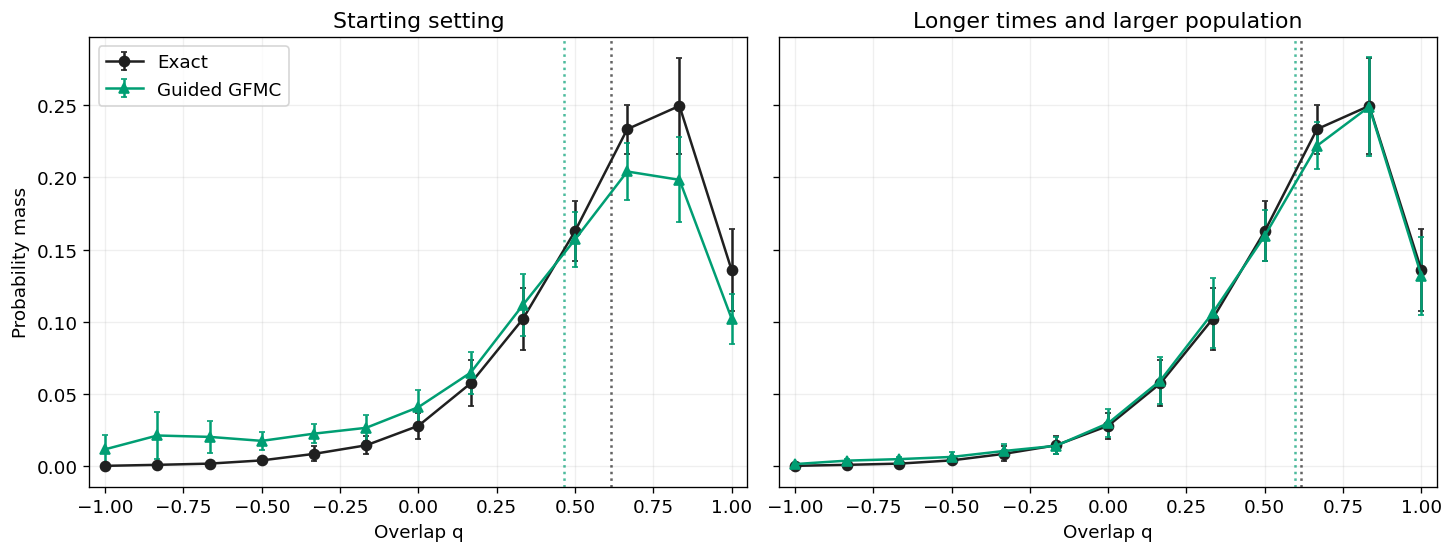

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout='constrained')
for ax, setting, title in zip(axes, ['baseline', 'equilibration8'],
                             ['Starting setting', 'Longer times and larger population']):
    d = hist[hist.setting == setting]
    for key, label, color, marker in [('exact', 'Exact', '#202020', 'o'),
                                       ('mc', 'Guided GFMC', '#009E73', '^')]:
        g = d.groupby('q')[key].agg(['mean', 'std', 'count']).sort_index()
        ax.errorbar(g.index, g['mean'], yerr=g['std']/np.sqrt(g['count']),
                    marker=marker, color=color, capsize=2, label=label)
        mean_q = np.dot(g.index.to_numpy(), g['mean'])
        ax.axvline(mean_q, color=color, linestyle=':', alpha=.7)
    ax.set(title=title, xlabel='Overlap q', xlim=(-1.05, 1.05))
    ax.grid(alpha=.2)
axes[0].set_ylabel('Probability mass')
axes[0].legend()
save(fig, 'disorder_averaged_pq')
plt.show()

## Does Monte Carlo reproduce the exact squared overlap?

For each disorder we check the two exact calculations agree:

$$\langle q^2\rangle_J=\frac1{N^2}\sum_{i,j}\langle Z_iZ_j\rangle_J^2
=\sum_q q^2P_J(q).$$

We then average over disorders. The table gives the exact and MC averages, their
disorder standard errors, and the MC-minus-exact difference paired on the same
disorders. Paired differences are more informative than overlap of the two large
disorder error bars. The last column measures MC uncertainty conditional on these
eight fixed disorders, using the four independent runs; it is not added again to
the main disorder errors.

,setting,exact,exact_se,mc,mc_se,difference,difference_se,conditional_mc_se
1,baseline,0.470877,0.044464,0.427580,0.042264,-0.043297,0.014289,0.004400
4,population2048,0.470877,0.044464,0.432411,0.043673,-0.038465,0.010738,0.002904
7,forward4,0.470877,0.044464,0.450793,0.043507,-0.020084,0.006596,0.003221
10,forward8,0.470877,0.044464,0.456136,0.047067,-0.014740,0.007861,0.003340
13,equilibration8,0.470877,0.044464,0.466575,0.044616,-0.004301,0.002126,0.003500


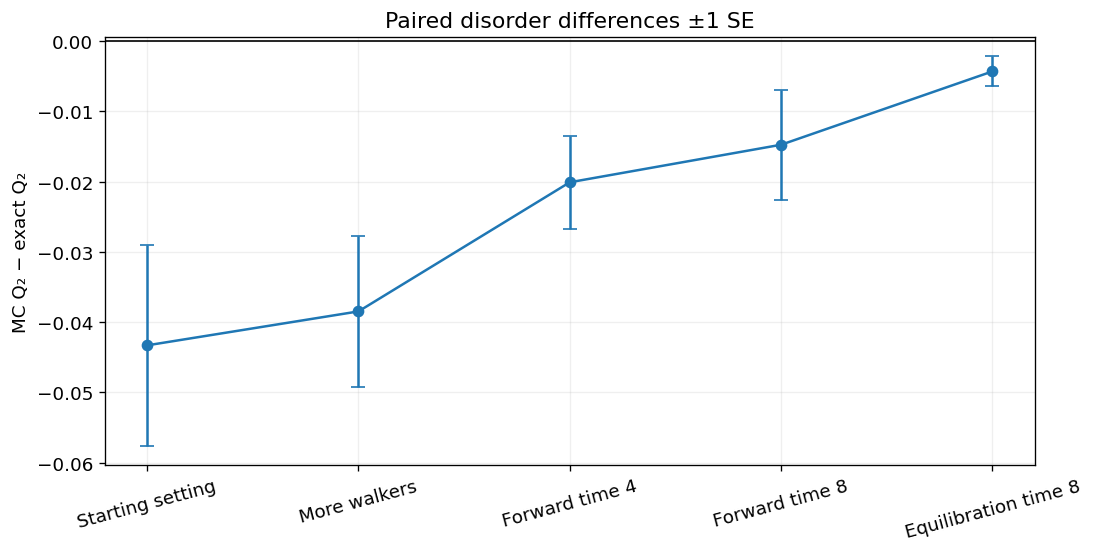

In [3]:
table = summary.copy()
table['setting'] = pd.Categorical(table.setting, order, ordered=True)
table = table.sort_values(['setting', 'observable'])
display(table[table.observable == 'q2'][['setting', 'exact', 'exact_se', 'mc', 'mc_se',
               'difference', 'difference_se', 'conditional_mc_se']].round(6))
q2 = table[table.observable == 'q2'].set_index('setting').loc[order]
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.errorbar(range(5), q2.difference, yerr=q2.difference_se, fmt='o-', capsize=4)
ax.axhline(0, color='black', linewidth=1)
ax.set(xticks=range(5), xticklabels=labels, ylabel='MC Q₂ − exact Q₂',
       title='Paired disorder differences ±1 SE')
ax.tick_params(axis='x', labelrotation=15)
ax.grid(alpha=.2)
save(fig, 'q2_paired_error')
plt.show()

## Check projection time separately from Monte Carlo noise

The deterministic finite-time reference computes what this same forward estimator
would produce with infinitely many walkers. Its difference from the exact ground
state measures finite-projection bias. Its calculation uses matrix exponentials,
not stochastic sampling. The plotted reference is averaged over the same eight
disorders and the actual eight cycle times.

The final two settings change only equilibration time. They do not increase the
forward time beyond 8. Agreement in one moment does not guarantee agreement of
the full distribution or all observables.

,finite_q2_error,mean_finite_TV,max_finite_TV,mean_MC_TV,alarms,worst_descendant_ESS,largest_lineage
setting,,,,,,,
baseline,-0.035430,0.085145,0.185739,0.132367,2,3.530464,0.525391
population2048,-0.035430,0.085145,0.185739,0.130287,0,28.362889,0.183105
forward4,-0.016799,0.042709,0.091200,0.088089,0,11.624045,0.270020
forward8,-0.006520,0.017025,0.048999,0.059578,7,2.816183,0.590332
equilibration8,-0.005508,0.013462,0.044143,0.033152,5,1.997158,0.703125


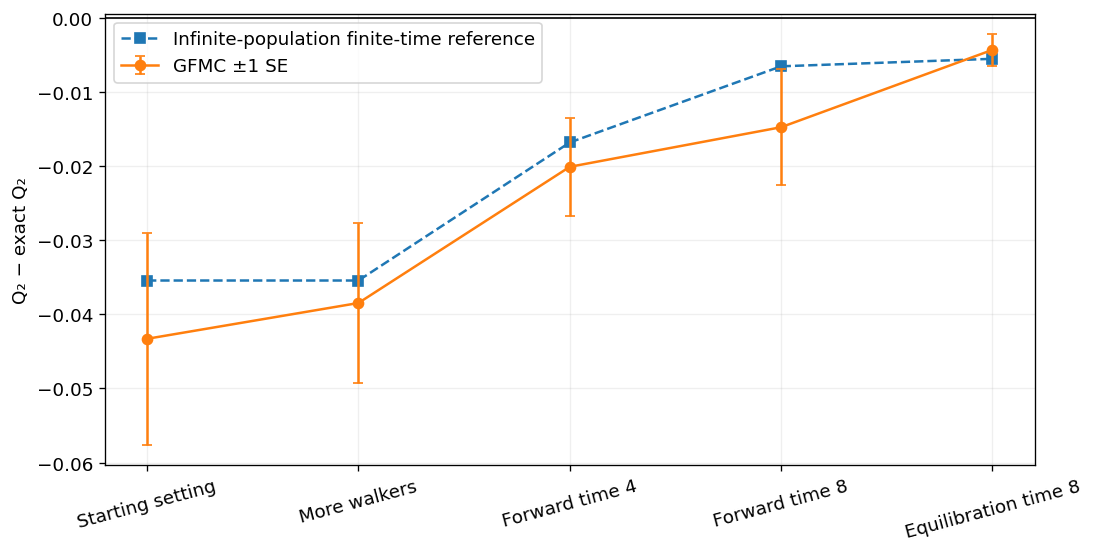

,first,second,observable,difference,se
0,baseline,population2048,q,-0.009245,0.024457
1,baseline,population2048,q2,0.004832,0.005129
2,baseline,population2048,chi_connected,-0.299114,0.254031
3,population2048,forward4,q,0.051935,0.025509
4,population2048,forward4,q2,0.018381,0.004406
5,population2048,forward4,chi_connected,-0.444291,0.403585
6,forward4,forward8,q,0.048642,0.041947
7,forward4,forward8,q2,0.005344,0.004804
8,forward4,forward8,chi_connected,-0.286691,0.307365
9,forward8,equilibration8,q,0.037586,0.024001


In [4]:
finite_rows = []
for setting in order:
    d = by_disorder[by_disorder.setting == setting]
    finite_rows.append(dict(setting=setting,
        finite_q2_error=(d.q2_finite-d.q2_exact).mean(),
        mean_finite_TV=d.finite_TV.mean(), max_finite_TV=d.finite_TV.max(),
        mean_MC_TV=d.mc_TV.mean(), alarms=int(d.alarms.sum()),
        worst_descendant_ESS=d.min_ess.min(), largest_lineage=d.max_lineage.max()))
finite_table = pd.DataFrame(finite_rows).set_index('setting').loc[order]
display(finite_table.round(6))
finite_table.to_csv(DATA/'finite_time_and_ancestry.csv')
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
ax.plot(range(5), finite_table.finite_q2_error, 's--', label='Infinite-population finite-time reference')
ax.errorbar(range(5), q2.difference, yerr=q2.difference_se, fmt='o-', capsize=3, label='GFMC ±1 SE')
ax.axhline(0, color='black', linewidth=1)
ax.set(xticks=range(5), xticklabels=labels, ylabel='Q₂ − exact Q₂')
ax.tick_params(axis='x', labelrotation=15)
ax.legend()
ax.grid(alpha=.2)
save(fig, 'projection_bias')
plt.show()
display(contrasts.round(6))

TV (total variation) compares complete distributions: zero means identical.
The MC value is a descriptive distance affected by noise, not an unbiased error
estimate. An ancestry alarm means at least one cycle has descendant ESS below 8
or one lineage exceeds half the population. All runs and alarms are retained.

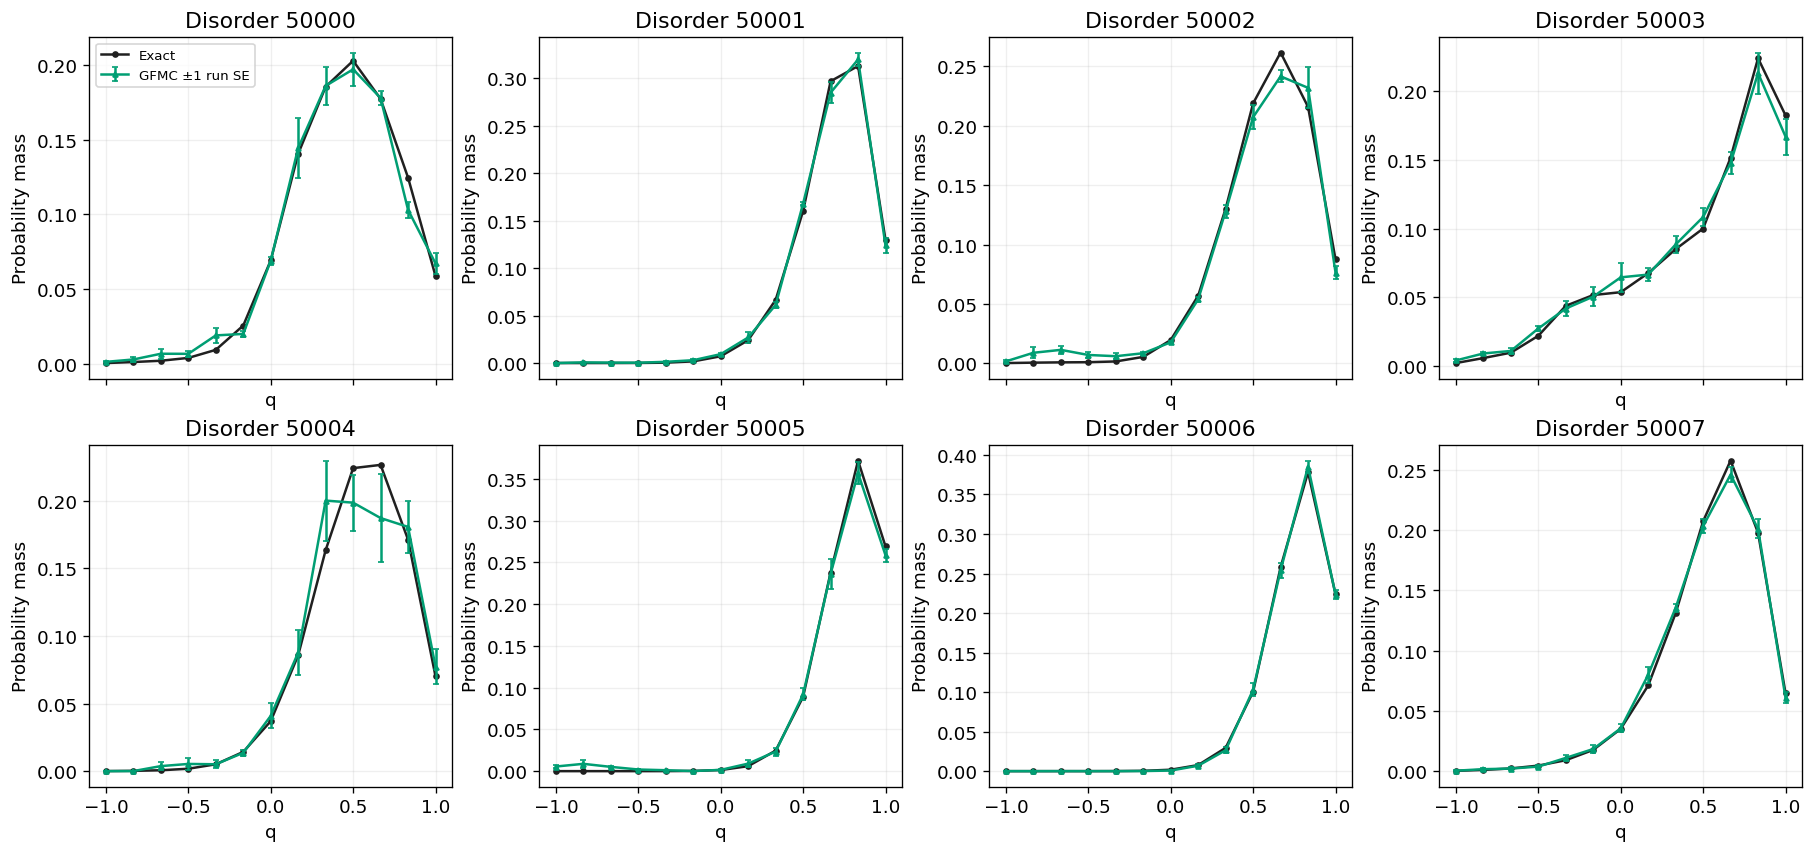

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, layout='constrained')
for ax, sid in zip(axes.flat, sorted(hist.sample_id.unique())):
    d = hist[(hist.setting == 'equilibration8') & (hist.sample_id == sid)].sort_values('q')
    ax.plot(d.q, d.exact, 'o-', color='#202020', markersize=3, label='Exact')
    ax.errorbar(d.q, d.mc, yerr=d.mc_se, fmt='^-', color='#009E73', markersize=3,
                capsize=2, label='GFMC ±1 run SE')
    ax.set(title=f'Disorder {sid}', xlabel='q', ylabel='Probability mass')
    ax.grid(alpha=.2)
axes[0,0].legend(fontsize=8)
save(fig, 'individual_disorders')
plt.show()

## What does this establish?

The benchmark tests exact/MC agreement and sensitivity to population and projection
times on the same eight disorders. The numerical summary below reports what was
measured. These are development data; no phase assignment or automatic production
qualification follows from completing the runs.

In [6]:
last = q2.loc['equilibration8']
first = q2.loc['baseline']
half = t.ppf(.975, 7)*last.difference_se
note = f"""**Exact disorder-averaged Q₂:** {last.exact:.6f} ± {last.exact_se:.6f} (one disorder SE).

**Starting GFMC Q₂:** {first.mc:.6f} ± {first.mc_se:.6f}.

**GFMC Q₂ at the end of the first ladder:** {last.mc:.6f} ± {last.mc_se:.6f}.

**Paired difference at that setting:** {last.difference:+.6f} ± {last.difference_se:.6f} (one SE).
An approximate pointwise 95% Student-t interval for the paired mean difference is
[{last.difference-half:+.6f}, {last.difference+half:+.6f}]. With eight disorders,
this interval is descriptive and assumes the mean differences are adequately approximated by a t interval.
An interval containing zero does not prove numerical equivalence.

**Finite-time Q₂ shift at the final setting:** {finite_table.loc['equilibration8', 'finite_q2_error']:+.6f}.
Mean per-disorder finite-time TV distance: {finite_table.loc['equilibration8', 'mean_finite_TV']:.6f}.

**Ancestry alarms across all settings:** {int(by_disorder.alarms.sum())}/160 runs.

This comparison uses one field point and one lattice size. A spin-glass phase requires
additional size-dependent evidence and checks for ordinary magnetic order.
"""
display(Markdown(note))
(DATA/'RESULTS.md').write_text('# Eight-disorder overlap benchmark\n\n'+note)

**Exact disorder-averaged Q₂:** 0.470877 ± 0.044464 (one disorder SE).

**Starting GFMC Q₂:** 0.427580 ± 0.042264.

**GFMC Q₂ at the end of the first ladder:** 0.466575 ± 0.044616.

**Paired difference at that setting:** -0.004301 ± 0.002126 (one SE).
An approximate pointwise 95% Student-t interval for the paired mean difference is
[-0.009329, +0.000726]. With eight disorders,
this interval is descriptive and assumes the mean differences are adequately approximated by a t interval.
An interval containing zero does not prove numerical equivalence.

**Finite-time Q₂ shift at the final setting:** -0.005508.
Mean per-disorder finite-time TV distance: 0.013462.

**Ancestry alarms across all settings:** 14/160 runs.

This comparison uses one field point and one lattice size. A spin-glass phase requires
additional size-dependent evidence and checks for ordinary magnetic order.


919

## Reproducibility

The [campaign directory](../data/kagome/overlap_disorder_benchmark_v1/) contains
the manifest, frozen source, per-run histograms, scalar moments, ancestry,
finite-time references and CSV tables. Input archives were verified by SHA-256;
every measured cycle was checked for histogram normalization and agreement with
the first, second and fourth scalar overlap moments. All run seeds are distinct.

Four verified baseline runs for disorder 50000 were reused from the earlier
campaign and retain their original provenance. The other 156 runs were executed
on AutoDL. Runtime totals for the reused runs refer to their original execution.

Regenerate the tables with `PYTHONPATH=code python -m transformer_qmc.overlap_disorder_benchmark --report-only`.
Regenerate this executed notebook with `PYTHONPATH=code python -m transformer_qmc.report_overlap_disorder`.
The latter reads saved outputs and creates plots; it launches no simulations.

## Stronger check: longer projection and a second population comparison

The first time ladder left measurable deterministic projection bias. A separate
AutoDL campaign therefore uses equilibration time 16 and forward time 32 for every
disorder, with populations 2048 and 4096. Four independent runs per disorder at
each population give 64 additional runs. The population contrast changes only
walker count; comparison with the earlier campaign changes both time settings.

Time 32 was selected using a deterministic screen over all eight disorders at
times 16, 32 and 64. This is development-driven refinement. All new runs use
independent seeds and retain every ancestry alarm. Four CPU workers run concurrently
on AutoDL with one thread per numerical library.

,setting,observable,exact,exact_se,mc,mc_se,difference,difference_se,conditional_mc_se,alarms,minimum_ess,largest_lineage
2,w2048_time32,q2,0.470877,0.044464,0.478366,0.043319,0.007489,0.008243,0.006760,22,1.000000,1.000000
5,w4096_time32,q2,0.470877,0.044464,0.471477,0.045025,0.000601,0.005201,0.006359,9,1.002934,0.998535


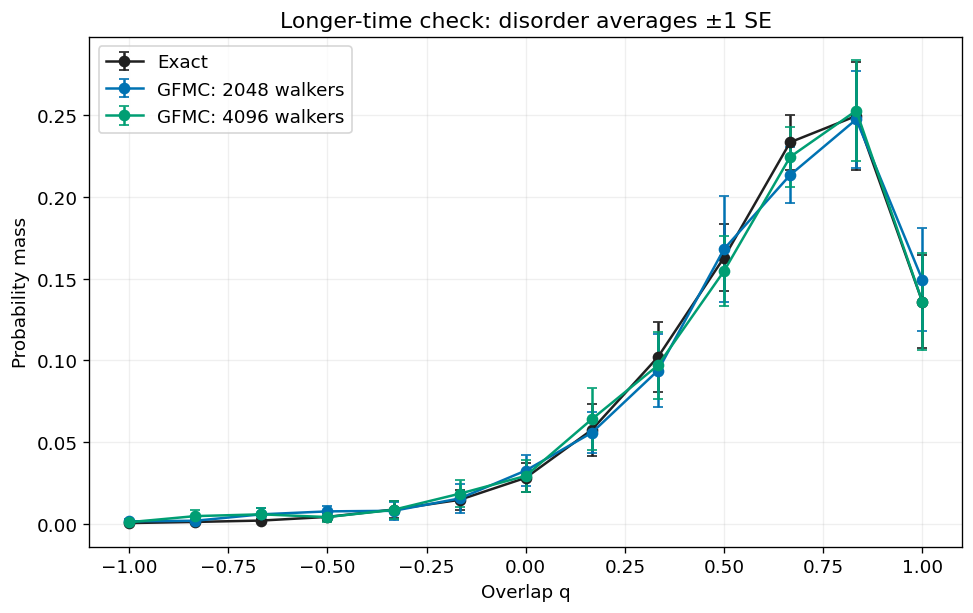

,observable,difference,se
0,q,-0.006680,0.009259
1,q2,-0.006889,0.011416
2,chi_connected,-0.001893,0.042642


**Longer-time Q₂, 4096 walkers:** 0.471477 ± 0.045025 (one disorder SE).

**Exact:** 0.470877 ± 0.044464.

**Paired difference:** +0.000601 ± 0.005201 (one SE).

**Ancestry alarms:** 9/32 runs at 4096 walkers; worst descendant ESS 1.00.

The deterministic time32 screen has mean Q₂ bias about −0.00054 and maximum
per-disorder TV about 0.0068. Finite-population and sampling effects remain additional.
These checks provide a stronger small-system comparison, not a thermodynamic phase assignment.


**Additional observables:** q is the finite-system mean overlap; chi_connected measures squared connected spin correlations. Their convergence can differ from Q₂.

,setting,observable,exact,exact_se,mc,mc_se,difference,difference_se,conditional_mc_se,alarms,minimum_ess,largest_lineage
0,w2048_time32,chi_connected,0.358947,0.090205,0.360476,0.077796,0.001529,0.030176,0.021640,22,1.000000,1.000000
1,w2048_time32,q,0.614455,0.043985,0.606615,0.037984,-0.007840,0.016463,0.013405,22,1.000000,1.000000
3,w4096_time32,chi_connected,0.358947,0.090205,0.358583,0.092754,-0.000364,0.014553,0.016936,9,1.002934,0.998535
4,w4096_time32,q,0.614455,0.043985,0.599935,0.039944,-0.014521,0.009107,0.009391,9,1.002934,0.998535


In [7]:
import hashlib
LONG = ROOT/'data/kagome/overlap_disorder_long_time_v1'
long_status = json.loads((LONG/'status.json').read_text())
assert long_status['completed_runs'] == long_status['expected_runs'] == 64
long_manifest = json.loads((LONG/'manifest.json').read_text())
for relative, digest in long_manifest['source_sha256'].items():
    assert hashlib.sha256((LONG/'source'/relative).read_bytes()).hexdigest() == digest
long_rows, long_bins, long_seeds = [], [], []
for setting, parameters in long_manifest['settings'].items():
    for sid in long_manifest['sample_ids']:
        stem = f'L2_s{sid}_g0p5_h0p15_K1'
        ref = json.loads((LONG/setting/f'{stem}_reference.json').read_text())
        for relative, digest in ref['input_sha256'].items():
            assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest() == digest
        records = [json.loads((LONG/setting/f'{stem}_repeat{r}.json').read_text()) for r in range(4)]
        qbins = np.array(ref['q'])
        for repeat, record in enumerate(records):
            assert record['sample_id'] == sid and record['repeat'] == repeat
            assert record['parameters'] == parameters
            assert record['input_sha256'] == ref['input_sha256']
            long_seeds.append(record['seed'])
            cycles = np.array(record['result']['pq_cycles'])
            assert np.isfinite(cycles).all() and (cycles >= 0).all()
            np.testing.assert_allclose(cycles.sum(1), 1., atol=1e-12)
            np.testing.assert_allclose(cycles.mean(0), record['result']['pq'], atol=1e-12)
            for power, key in [(1, 'q'), (2, 'q2'), (4, 'q4')]:
                np.testing.assert_allclose(cycles @ qbins**power, record['result'][key+'_cycles'], atol=1e-12)
        values = np.array([r['result']['pq'] for r in records])
        for key in ['q', 'q2', 'chi_connected']:
            mc = np.array([r['result'][key] for r in records])
            long_rows.append(dict(setting=setting, sample_id=sid, observable=key,
                exact=ref['exact_observables'][key], mc=mc.mean(), run_se=mc.std(ddof=1)/2,
                alarms=sum(r['ancestry_alarm'] for r in records),
                minimum_ess=min(min(r['result']['descendant_ess']) for r in records),
                largest_lineage=max(max(r['result']['largest_lineage']) for r in records)))
        for k, value in enumerate(qbins):
            long_bins.append(dict(setting=setting, sample_id=sid, q=value, exact=ref['exact'][k],
                mc=values[:,k].mean(), finite_time=ref['finite_time'][k]))
old_seeds = [json.loads(p.read_text())['seed'] for p in DATA.glob('*/*_repeat*.json')]
assert len(set(old_seeds+long_seeds)) == 224
long_df, long_hist = pd.DataFrame(long_rows), pd.DataFrame(long_bins)
long_df.to_csv(LONG/'by_disorder.csv', index=False)
long_hist.to_csv(LONG/'histograms.csv', index=False)
long_summary=[]
for (setting,key), d in long_df.groupby(['setting','observable']):
    diff = d.mc-d.exact
    long_summary.append(dict(setting=setting, observable=key, exact=d.exact.mean(),
        exact_se=d.exact.std(ddof=1)/np.sqrt(8), mc=d.mc.mean(), mc_se=d.mc.std(ddof=1)/np.sqrt(8),
        difference=diff.mean(), difference_se=diff.std(ddof=1)/np.sqrt(8),
        conditional_mc_se=np.sqrt(np.sum(d.run_se**2))/8,
        alarms=int(d.alarms.sum()), minimum_ess=d.minimum_ess.min(), largest_lineage=d.largest_lineage.max()))
long_summary=pd.DataFrame(long_summary)
long_summary.to_csv(LONG/'summary.csv', index=False)
display(long_summary[long_summary.observable == 'q2'].round(6))
fig, ax = plt.subplots(figsize=(8,5), layout='constrained')
for setting,key,label,color in [('w4096_time32','exact','Exact','#202020'),
                                ('w2048_time32','mc','GFMC: 2048 walkers','#0072B2'),
                                ('w4096_time32','mc','GFMC: 4096 walkers','#009E73')]:
    d=long_hist[long_hist.setting==setting].groupby('q')[key].agg(['mean','std'])
    ax.errorbar(d.index,d['mean'],yerr=d['std']/np.sqrt(8),fmt='o-',capsize=3,label=label,color=color)
ax.set(xlabel='Overlap q',ylabel='Probability mass',title='Longer-time check: disorder averages ±1 SE')
ax.legend()
ax.grid(alpha=.2)
save(fig,'long_time_pq')
plt.show()
pop=[]
for key in ['q','q2','chi_connected']:
    d=long_df[long_df.observable==key].pivot(index='sample_id',columns='setting',values='mc')
    diff=d.w4096_time32-d.w2048_time32
    pop.append(dict(observable=key,difference=diff.mean(),se=diff.std(ddof=1)/np.sqrt(8)))
display(pd.DataFrame(pop).round(6))
pd.DataFrame(pop).to_csv(LONG/'population_contrast.csv',index=False)
best=long_summary[(long_summary.setting=='w4096_time32') & (long_summary.observable=='q2')].iloc[0]
note_long=f"""**Longer-time Q₂, 4096 walkers:** {best.mc:.6f} ± {best.mc_se:.6f} (one disorder SE).

**Exact:** {best.exact:.6f} ± {best.exact_se:.6f}.

**Paired difference:** {best.difference:+.6f} ± {best.difference_se:.6f} (one SE).

**Ancestry alarms:** {int(best.alarms)}/32 runs at 4096 walkers; worst descendant ESS {best.minimum_ess:.2f}.

The deterministic time32 screen has mean Q₂ bias about −0.00054 and maximum
per-disorder TV about 0.0068. Finite-population and sampling effects remain additional.
These checks provide a stronger small-system comparison, not a thermodynamic phase assignment.
"""
display(Markdown(note_long))
(LONG/'RESULTS.md').write_text('# Longer-time overlap benchmark\n\n'+note_long)
display(Markdown('**Additional observables:** q is the finite-system mean overlap; '
                 'chi_connected measures squared connected spin correlations. '
                 'Their convergence can differ from Q₂.'))
display(long_summary[long_summary.observable != 'q2'].round(6))

## Next decision

The matched eight-disorder workflow is now available. The starting settings have
measurable projection bias, and increasing projection time can worsen ancestry.
Choose subsequent settings using the exact errors, population sensitivity and
ancestry together. Agreement of a noisy mean alone does not certify convergence.

Before expanding to a phase study, tighten this small-system convergence check
where needed. Larger-size phase inference is a later milestone: this notebook
does not launch the zero-field size scan or assign a thermodynamic phase.
For massive campaigns, AutoDL remains the main compute platform; measure GPU
batching and CPU/GPU concurrency for the direct-inference workload before
committing the larger resource budget.